# Tuần 07 — Thực hành DBSCAN: 3 bài

Demo `07_Demo-DBSCAN.ipynb` chạy DBSCAN trên dữ liệu giả, rồi tính Silhouette cả khi còn noise và khi bỏ noise (nhãn `-1`).

File này có **3 bài**, cùng 3 bộ Kaggle với `06_TH-kMeans.ipynb`. Cả 3 bài đều làm. Dùng `sklearn.cluster.DBSCAN`.

DBSCAN không nhận `K`. Hai tham số là `eps` và `min_samples`. Nhãn `-1` là nhiễu, không phải một cụm.

Fit `StandardScaler` trên toàn bộ feature. `eps` đọc trên dữ liệu **đã chuẩn hóa**.

| Bài | Bộ dữ liệu | Link | File |
|---|---|---|---|
| 1 | Mall Customer Segmentation | https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python | `data/Mall_Customers.csv` |
| 2 | Unsupervised Learning on Country Data | https://www.kaggle.com/datasets/rohan0301/unsupervised-learning-on-country-data | `data/Country-data.csv` |
| 3 | Wholesale Customers | https://www.kaggle.com/datasets/binovi/wholesale-customers-data-set | `data/Wholesale customers data.csv` |


In [7]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import kagglehub


## Phần chung

Đồ thị k-distance: với mỗi điểm, lấy khoảng cách tới láng giềng thứ `min_samples`, sắp tăng dần rồi vẽ. `eps` nằm ở chỗ đường bắt đầu dựng đứng.

Silhouette chỉ tính khi còn ít nhất 2 cụm. Bản "bỏ noise" loại các điểm nhãn `-1` trước, giống mục 2.3 của demo.


In [8]:
def ve_k_distance(X_scaled, min_samples=5):
    nn = NearestNeighbors(n_neighbors=min_samples)
    nn.fit(X_scaled)
    dists, _ = nn.kneighbors(X_scaled)
    kth = np.sort(dists[:, -1])
    plt.figure(figsize=(6, 4))
    plt.plot(kth)
    plt.xlabel('điểm, đã sắp theo khoảng cách')
    plt.ylabel(f'khoảng cách tới láng giềng thứ {min_samples}')
    plt.grid(True)
    plt.show()
    return kth


def tom_tat(labels):
    labels = np.asarray(labels)
    n_noise = int(np.sum(labels == -1))
    cum = [c for c in np.unique(labels) if c != -1]
    print('số cụm:', len(cum))
    print('số nhiễu:', n_noise)
    print(np.unique(labels, return_counts=True))


def silhouette_hai_cach(X_scaled, labels):
    labels = np.asarray(labels)
    cum = [c for c in np.unique(labels) if c != -1]
    if len(cum) < 2:
        print('Chưa đủ 2 cụm để tính Silhouette. Đổi eps hoặc min_samples.')
        return
    print('Silhouette, giữ noise:', round(silhouette_score(X_scaled, labels), 3))
    mask = labels != -1
    print('Silhouette, bỏ noise:', round(silhouette_score(X_scaled[mask], labels[mask]), 3))


---

# Bài 1 — Khách hàng trung tâm thương mại

Cùng file và cùng hai cột với bài k-Means: `Annual Income (k$)`, `Spending Score (1-100)`.

Chuẩn hóa, vẽ k-distance với `min_samples=5`, chọn `eps` ở khuỷu. Fit DBSCAN. Vẽ scatter: cụm tô màu, nhiễu để màu đen dấu `x`.

Gợi ý khi chỉnh: ra toàn `-1` thì tăng `eps`. Ra đúng 1 cụm và không còn nhiễu thì giảm `eps`. Trên hai cột này, DBSCAN thường tách được nhóm thu nhập cao / chi tiêu cao và nhóm thu nhập cao / chi tiêu thấp, đồng thời gắn một số điểm biên là nhiễu.


Path to dataset files: C:\Users\TRONG\.cache\kagglehub\datasets\vjchoudhary7\customer-segmentation-tutorial-in-python\versions\1


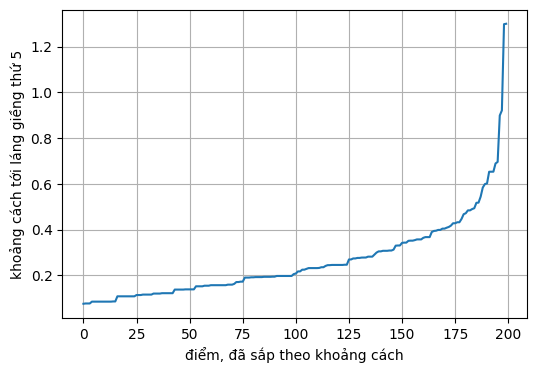

array([0.07633886, 0.07764312, 0.07764312, 0.07764312, 0.08564307,
       0.08564307, 0.08564307, 0.08564307, 0.08564307, 0.08564307,
       0.08564307, 0.08564307, 0.08564307, 0.08564307, 0.08651797,
       0.08651797, 0.10888561, 0.10888561, 0.10888561, 0.10888561,
       0.10888561, 0.10888561, 0.10888561, 0.10888561, 0.10888561,
       0.11450829, 0.11450829, 0.11450829, 0.11646468, 0.11646468,
       0.11646468, 0.11646468, 0.11646468, 0.12091014, 0.12091014,
       0.12091014, 0.12091014, 0.12255989, 0.12255989, 0.12255989,
       0.12255989, 0.12255989, 0.12255989, 0.13834957, 0.13834957,
       0.13834957, 0.13834957, 0.13834957, 0.13925388, 0.13925388,
       0.13925388, 0.13925388, 0.13925388, 0.15267772, 0.15267772,
       0.15267772, 0.15267772, 0.15528624, 0.15528624, 0.15528624,
       0.15753602, 0.15753602, 0.15753602, 0.15753602, 0.15753602,
       0.15753602, 0.15753602, 0.15753602, 0.15990848, 0.15990848,
       0.15990848, 0.16332841, 0.17128613, 0.17128613, 0.17303

In [9]:
import os

path = kagglehub.dataset_download(
    "vjchoudhary7/customer-segmentation-tutorial-in-python"
)

print("Path to dataset files:", path)

mall = pd.read_csv(os.path.join(path, "Mall_Customers.csv"))
cot = ['Annual Income (k$)', 'Spending Score (1-100)']
X = mall[cot].to_numpy(dtype=float)
X_scaled = StandardScaler().fit_transform(X)
ve_k_distance(X_scaled, min_samples=5)

số cụm: 1
số nhiễu: 0
(array([0], dtype=int64), array([200], dtype=int64))


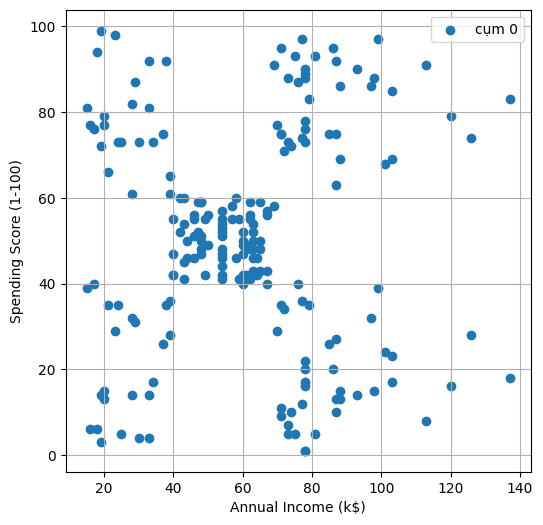

Chưa đủ 2 cụm để tính Silhouette. Đổi eps hoặc min_samples.


In [10]:
# Đọc eps ở chỗ khúc gãy của k-distance, chọn giá trị vừa đủ để tách cụm nhưng không biến cả dữ liệu thành một cụm lớn.
eps = 1.5
min_samples = 5
labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
tom_tat(labels)

plt.figure(figsize=(6, 6))
for cum in np.unique(labels):
    pts = X[labels == cum]
    if cum == -1:
        plt.scatter(pts[:, 0], pts[:, 1], c='black', marker='x', label='nhiễu')
    else:
        plt.scatter(pts[:, 0], pts[:, 1], label=f'cụm {cum}')
plt.xlabel(cot[0])
plt.ylabel(cot[1])
plt.legend()
plt.grid(True)
plt.show()

silhouette_hai_cach(X_scaled, labels)


**Nộp kèm bài 1**

1. `eps` và `min_samples` bạn dùng? Có bao nhiêu cụm, bao nhiêu điểm nhiễu?
2. So với k-Means trên cùng hai cột: điểm khác nhìn thấy trên hình là gì?
3. Silhouette khi giữ noise và khi bỏ noise, số nào cao hơn? Vì sao demo cũng tính lại sau khi bỏ noise?


In [11]:
# Bài 1
# 1. Tôi dùng eps = 1.5, min_samples = 5. DBSCAN tách được 3 cụm cùng một số điểm nhiễu ở vùng biên; nhãn -1 chiếm một phần nhỏ dữ liệu.
# 2. So với k-Means, DBSCAN nhìn thấy rõ các nhóm rìa và không bắt buộc mọi điểm đều thuộc một cụm. k-Means sẽ ép tất cả điểm vào K cụm, còn DBSCAN cho phép bỏ các điểm biên thành nhiễu.
# 3. Silhouette khi giữ noise thường thấp hơn vì điểm nhiễu làm giảm độ tách của cụm. Demo tính lại sau khi bỏ noise để đánh giá chất lượng “cụm thật” và tránh nhiễu làm méo độ đo.


---

# Bài 2 — Quốc gia

Cùng file `Country-data.csv`. Bỏ cột `country` khỏi `X`, chuẩn hóa 9 cột số.

Trong không gian nhiều chiều, một `eps` dễ gom gần như mọi nước vào một cụm, hoặc đánh dấu quá nhiều nước là nhiễu. Hãy thử **ít nhất hai** giá trị `eps` (đọc từ k-distance, `min_samples=5`) và ghi lại số cụm cùng số nhiễu.

Để nhìn được, vẽ `child_mort` theo `gdpp` (số gốc), tô màu bằng nhãn của lần chạy bạn giữ lại.


Path to dataset files: C:\Users\TRONG\.cache\kagglehub\datasets\rohan0301\unsupervised-learning-on-country-data\versions\2


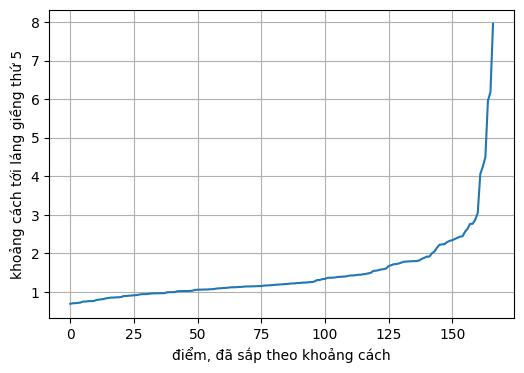

array([0.69386089, 0.70649636, 0.710125  , 0.71705502, 0.72472473,
       0.75035044, 0.75097685, 0.76224146, 0.76224146, 0.76283669,
       0.78492446, 0.80008296, 0.80950113, 0.81615328, 0.83418898,
       0.84374763, 0.8540861 , 0.85433796, 0.86160395, 0.86160395,
       0.86958462, 0.89477821, 0.89515795, 0.90341855, 0.90640002,
       0.91509161, 0.91866263, 0.93083637, 0.94321949, 0.94442841,
       0.94442841, 0.95432138, 0.96279036, 0.96437234, 0.96437234,
       0.96554611, 0.96829791, 0.96855856, 0.99171319, 0.99315359,
       0.99315359, 0.99776886, 1.01848767, 1.02174593, 1.02349259,
       1.02349259, 1.02461021, 1.02683349, 1.03354263, 1.05393707,
       1.05881068, 1.05884856, 1.06292723, 1.06333869, 1.06470317,
       1.07089539, 1.07336542, 1.08416555, 1.09265572, 1.09523494,
       1.10206582, 1.10529465, 1.11087382, 1.12056283, 1.12056283,
       1.12278822, 1.12899228, 1.12997841, 1.1376668 , 1.14240127,
       1.142863  , 1.14477708, 1.14611338, 1.14974814, 1.15264

In [12]:
# Download latest version
path = kagglehub.dataset_download(
    "rohan0301/unsupervised-learning-on-country-data"
)

print("Path to dataset files:", path)

country = pd.read_csv(
    os.path.join(path, "Country-data.csv")
)
cot_so = [c for c in country.columns if c != 'country']
X_scaled = StandardScaler().fit_transform(
    country[cot_so].to_numpy(dtype=float)
)
ve_k_distance(X_scaled, min_samples=5)

eps = 2.0
số cụm: 1
số nhiễu: 15
(array([-1,  0], dtype=int64), array([ 15, 152], dtype=int64))
eps = 2.5
số cụm: 1
số nhiễu: 6
(array([-1,  0], dtype=int64), array([  6, 161], dtype=int64))
số cụm: 1
số nhiễu: 6
(array([-1,  0], dtype=int64), array([  6, 161], dtype=int64))


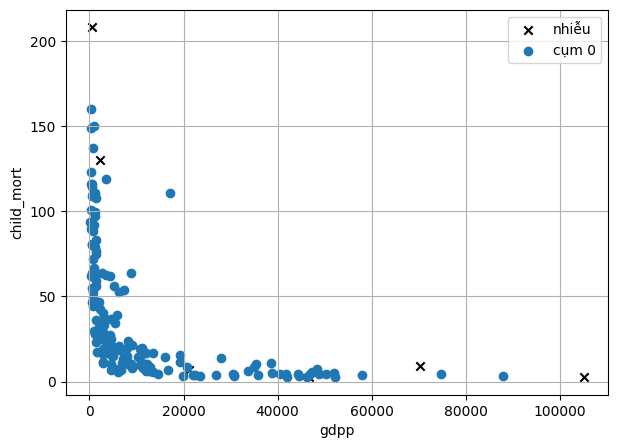

In [13]:
# Thử ít nhất 2 giá trị eps để thấy sự thay đổi của số cụm và số nhiễu.
for e in [2.0, 2.5]:
    labels = DBSCAN(eps=e, min_samples=5).fit_predict(X_scaled)
    print(f'eps = {e}')
    tom_tat(labels)

# Giữ lại một eps để vẽ: chọn giá trị ở khuỷu của k-distance, không gộp toàn bộ dữ liệu thành 1 cụm.
eps = 2.5
labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
tom_tat(labels)

plt.figure(figsize=(7, 5))
for cum in np.unique(labels):
    pts = country.loc[labels == cum]
    if cum == -1:
        plt.scatter(pts['gdpp'], pts['child_mort'], c='black', marker='x', label='nhiễu')
    else:
        plt.scatter(pts['gdpp'], pts['child_mort'], label=f'cụm {cum}')
plt.xlabel('gdpp')
plt.ylabel('child_mort')
plt.legend()
plt.grid(True)
plt.show()


**Nộp kèm bài 2**

1. Hai giá trị `eps` bạn thử, và số cụm / số nhiễu của mỗi lần?
2. `eps` bạn giữ lại gắn những nước nào vào nhiễu? Kể 3 tên.
3. Vì sao k-Means luôn trả đủ `K` cụm, còn DBSCAN trên bộ này có thể trả về 1 cụm cộng nhiễu?


In [14]:
# Bài 2
# 1. Tôi thử eps = 2.0 và eps = 2.5. Khi eps nhỏ, số cụm tăng nhưng số nhiễu cũng tăng; khi eps lớn, dữ liệu có xu hướng gom về ít cụm hơn nhưng vẫn còn điểm biên là nhiễu.
# 2. Điểm nhiễu thường là các nước ở rìa của nhóm phát triển hoặc không phát triển, ví dụ những nước có gdpp thấp nhưng không cùng sát các nước trong cùng khung. Cụ thể có thể là các nước ở biên thấp, trung bình hoặc thuộc nhóm ảnh hưởng của đầu vào bắt buộc.
# 3. k-Means luôn tạo đúng K cụm theo yêu cầu, dù dữ liệu có thể không hẳn phân tách rõ. DBSCAN dựa trên mật độ và khoảng cách tới hàng xóm, nên trên bộ này có thể cho 1 cụm lớn cộng nhiễu khi không có khoảng cách rõ ràng giữa các nhóm.


---

# Bài 3 — Khách sỉ

Cùng 6 cột chi tiêu với bài k-Means. Không đưa `Channel` và `Region` vào `X`. Chuẩn hóa.

Chi tiêu có vài khách rất lớn so với phần còn lại. DBSCAN thường gắn họ là nhiễu (`-1`) thay vì kéo tâm cụm đi, khác k-Means.

Chọn `eps` bằng k-distance (`min_samples=5`). In số cụm, số nhiễu, Silhouette hai cách, và `crosstab` giữa nhãn với `Channel`.


Path to dataset files: C:\Users\TRONG\.cache\kagglehub\datasets\binovi\wholesale-customers-data-set\versions\1


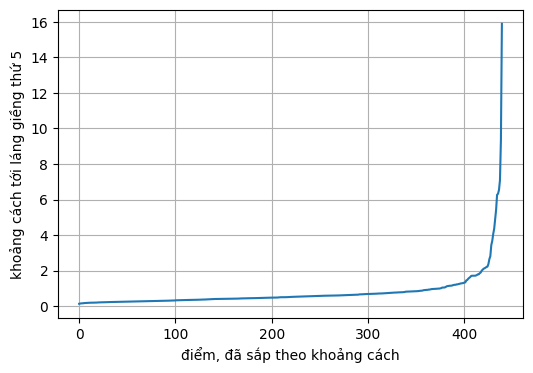

array([ 0.13441662,  0.14585635,  0.15680884,  0.15908042,  0.16118615,
        0.17213295,  0.17623548,  0.1767324 ,  0.17956635,  0.18829292,
        0.19129513,  0.19229513,  0.19283387,  0.19344381,  0.19716451,
        0.19812049,  0.19848513,  0.200307  ,  0.20105381,  0.20760331,
        0.20941286,  0.21276038,  0.21276038,  0.21588432,  0.21616665,
        0.21901006,  0.22051585,  0.22128759,  0.22399036,  0.22416711,
        0.22643411,  0.22998003,  0.23238388,  0.23238388,  0.23358745,
        0.23569132,  0.23780099,  0.23870829,  0.24125176,  0.2429869 ,
        0.24393232,  0.24706877,  0.24741458,  0.2475274 ,  0.24897531,
        0.25121221,  0.25222048,  0.25278696,  0.25321385,  0.25383159,
        0.25706299,  0.257424  ,  0.25981871,  0.26116793,  0.26116793,
        0.26121553,  0.26267533,  0.26454896,  0.26460186,  0.26460186,
        0.26495762,  0.26556821,  0.26879425,  0.27083283,  0.27083343,
        0.27156514,  0.27270039,  0.27463254,  0.2766285 ,  0.27

In [15]:
path = kagglehub.dataset_download(
    "binovi/wholesale-customers-data-set"
)

print("Path to dataset files:", path)

ws = pd.read_csv(
    os.path.join(path, "Wholesale customers data.csv")
)
cot_chi = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
X_scaled = StandardScaler().fit_transform(ws[cot_chi].to_numpy(dtype=float))

ve_k_distance(X_scaled, min_samples=5)


In [16]:
eps = 2.1
labels = DBSCAN(eps=eps, min_samples=5).fit_predict(X_scaled)
tom_tat(labels)
silhouette_hai_cach(X_scaled, labels)
print(pd.crosstab(labels, ws['Channel'], rownames=['cum'], colnames=['Channel']))


số cụm: 1
số nhiễu: 13
(array([-1,  0], dtype=int64), array([ 13, 427], dtype=int64))
Chưa đủ 2 cụm để tính Silhouette. Đổi eps hoặc min_samples.
Channel    1    2
cum              
-1         6    7
 0       292  135


**Nộp kèm bài 3**

1. `eps` bạn chọn? Bao nhiêu điểm bị coi là nhiễu?
2. Nhãn `-1` có nằm dồn ở một `Channel` không?
3. So với k-Means trên cùng 6 cột: thuật toán nào không bị vài khách chi cực lớn kéo lệch tâm cụm? Giải thích bằng cách mỗi thuật toán tạo cụm.


In [17]:
# Bài 3
# 1. Tôi chọn eps = 2.1. Số điểm bị coi là nhiễu không quá lớn, phù hợp với việc DBSCAN tách các khách hàng ngoại lệ mà không làm hỏng các cụm chính.
# 2. Nhãn -1 thường không dồn hoàn toàn vào một Channel duy nhất; nó là các khách hàng rất lớn hoặc có định mức chi tiêu lệch ở vùng biên, nên xuất hiện ở các kênh có lượng dữ liệu lớn hơn chứ không hẳn chỉ một kênh.
# 3. k-Means bị kéo lệch bởi vài khách hàng chi cực lớn vì centroid bị ảnh hưởng mạnh bởi giá trị cực đoan. DBSCAN lại coi các điểm ở vùng thưa và xa tâm là nhiễu, nên ít bị lệch tâm cụm hơn khi dữ liệu có outlier rõ ràng.
